In [3]:
import pandas as pd
import sqlite3
import time

# 1. 가상의 은행 데이터베이스(SQLite) 연결 (파일이 없으면 폴더에 'home_credit.db'가 새로 생성됩니다)
conn = sqlite3.connect('home_credit.db')
print("✅ 은행 데이터베이스(home_credit.db) 연결 완료!")


# 2. 대용량 CSV 파일을 메모리 폭발(OOM) 없이 DB에 넣는 함수 (Chunk 사이즈 조절)
def load_csv_to_db(csv_file, table_name, conn, chunksize=50000):
    start_time = time.time()
    print(f"[{table_name}] 테이블 적재 시작...")

    
    # 데이터를 한 번에 다 부르지 않고 5만 줄씩 잘라서(chunk) DB에 밀어 넣습니다.
    for i, chunk in enumerate(pd.read_csv(csv_file, chunksize=chunksize)):
        # if_exists='append' : 테이블이 있으면 그 밑에 계속 이어 붙임
        chunk.to_sql(table_name, conn, if_exists='append', index=False)
        print(f"   - {i+1}번째 덩어리(5만 줄) 적재 완료...")
        
    end_time = time.time()
    print(f"✅ [{table_name}] 적재 완료! (소요 시간: {end_time - start_time:.2f}초)\n")

# 3. 가장 핵심이 되는 두 개의 테이블 먼저 밀어넣기
# (나머지 파일들도 나중에 같은 방식으로 넣으면 됩니다)
try:
    # 고객 메인 정보 테이블
    load_csv_to_db('application_train.csv', 'application_train', conn)
    # 고객의 타 금융기관 대출 이력 테이블 (이후 SQL 조인(JOIN) 쿼리 최적화 연습용)
    load_csv_to_db('bureau.csv', 'bureau', conn)
    
except Exception as e:
    print("❌ 에러 발생:", e)

# 4. DB에 테이블이 잘 생성되었는지 확인
query = "SELECT name FROM sqlite_master WHERE type='table';"
tables = pd.read_sql(query, conn)
print("📌 현재 DB에 구축된 테이블 목록:\n", tables)

✅ 은행 데이터베이스(home_credit.db) 연결 완료!
[application_train] 테이블 적재 시작...
   - 1번째 덩어리(5만 줄) 적재 완료...
   - 2번째 덩어리(5만 줄) 적재 완료...
   - 3번째 덩어리(5만 줄) 적재 완료...
   - 4번째 덩어리(5만 줄) 적재 완료...
   - 5번째 덩어리(5만 줄) 적재 완료...
   - 6번째 덩어리(5만 줄) 적재 완료...
   - 7번째 덩어리(5만 줄) 적재 완료...
✅ [application_train] 적재 완료! (소요 시간: 7.74초)

[bureau] 테이블 적재 시작...
   - 1번째 덩어리(5만 줄) 적재 완료...
   - 2번째 덩어리(5만 줄) 적재 완료...
   - 3번째 덩어리(5만 줄) 적재 완료...
   - 4번째 덩어리(5만 줄) 적재 완료...
   - 5번째 덩어리(5만 줄) 적재 완료...
   - 6번째 덩어리(5만 줄) 적재 완료...
   - 7번째 덩어리(5만 줄) 적재 완료...
   - 8번째 덩어리(5만 줄) 적재 완료...
   - 9번째 덩어리(5만 줄) 적재 완료...
   - 10번째 덩어리(5만 줄) 적재 완료...
   - 11번째 덩어리(5만 줄) 적재 완료...
   - 12번째 덩어리(5만 줄) 적재 완료...
   - 13번째 덩어리(5만 줄) 적재 완료...
   - 14번째 덩어리(5만 줄) 적재 완료...
   - 15번째 덩어리(5만 줄) 적재 완료...
   - 16번째 덩어리(5만 줄) 적재 완료...
   - 17번째 덩어리(5만 줄) 적재 완료...
   - 18번째 덩어리(5만 줄) 적재 완료...
   - 19번째 덩어리(5만 줄) 적재 완료...
   - 20번째 덩어리(5만 줄) 적재 완료...
   - 21번째 덩어리(5만 줄) 적재 완료...
   - 22번째 덩어리(5만 줄) 적재 완료...
   - 23번째 덩어리(5만 줄) 적재 완료...
   - 24번째 덩

In [4]:
import pandas as pd

# 1. 현업 스타일의 다중 테이블 JOIN 쿼리 작성 (SQLD 실전 압축!)
query = """
    SELECT 
        A.SK_ID_CURR,                   /* 고객 고유 ID */
        A.TARGET,                       /* 정답지: 연체 여부 (1=연체, 0=정상) */
        A.CODE_GENDER,                  /* 성별 */
        A.AMT_INCOME_TOTAL,             /* 현재 총소득 */
        A.AMT_CREDIT,                   /* 이번에 신청한 대출 금액 */
        
        /* B_AGG (서브쿼리)에서 집계해 온 과거 대출 이력 파생 변수들 */
        IFNULL(B_AGG.PAST_LOAN_COUNT, 0) AS PAST_LOAN_COUNT,      /* 과거 타기관 대출 횟수 (없으면 0) */
        IFNULL(B_AGG.TOTAL_PAST_DEBT, 0) AS TOTAL_PAST_DEBT       /* 과거 타기관 총 대출액 (없으면 0) */
        
    FROM application_train A
    
    /* 과거 대출 이력(bureau)을 고객ID(SK_ID_CURR) 기준으로 그룹화(GROUP BY)하는 서브쿼리 */
    LEFT JOIN (
        SELECT 
            SK_ID_CURR,
            COUNT(SK_ID_BUREAU) AS PAST_LOAN_COUNT,
            SUM(AMT_CREDIT_SUM) AS TOTAL_PAST_DEBT
        FROM bureau
        GROUP BY SK_ID_CURR
    ) B_AGG ON A.SK_ID_CURR = B_AGG.SK_ID_CURR
"""

# 2. SQLite DB에 쿼리를 전송하여 분석용 통합 데이터프레임(Data Mart)으로 뽑아오기
print("SQL 쿼리 실행 중... (데이터를 병합하고 집계하느라 수십 초 정도 걸릴 수 있습니다)")
df_mart = pd.read_sql_query(query, conn)

# 3. 결과 확인
print("✅ 분석용 통합 데이터 마트 구축 완료!")
print(f"총 데이터 형태: {df_mart.shape}")
df_mart.head()

SQL 쿼리 실행 중... (데이터를 병합하고 집계하느라 수십 초 정도 걸릴 수 있습니다)
✅ 분석용 통합 데이터 마트 구축 완료!
총 데이터 형태: (1845066, 7)


,SK_ID_CURR,TARGET,CODE_GENDER,AMT_INCOME_TOTAL,AMT_CREDIT,PAST_LOAN_COUNT,TOTAL_PAST_DEBT
0,100002,1,M,202500.0,406597.5,48,5190333.39
1,100003,0,F,270000.0,1293502.5,24,6104403.00
2,100004,0,M,67500.0,135000.0,12,1134226.80
3,100006,0,F,135000.0,312682.5,0,0.00
4,100007,0,M,121500.0,513000.0,6,877500.00


In [5]:
#면접관의 질문: "캐글 데이터는 보통 CSV 파일 하나로 분석하지 않나요? 굳이 DB를 왜 썼죠?"
#지원자의 답변 (방어 논리): "네, 많은 지원자가 판다스로 CSV 여러 개를 불러와서 pd.merge()를 씁니다. 하지만 실제 금융권 인프라 환경에서는 데이터가 RDBMS에 적재되어 있기 때문에, "
#"SQL의 LEFT JOIN과 GROUP BY 서브쿼리를 활용해 DB 단에서 먼저 연산을 처리하고 가벼운 결과만 파이썬으로 가져오는 것이 파이프라인 최적화의 정석이라고 생각하여 이렇게 구축했습니다."

=== 전체 고객 연체율 (Default Rate) ===
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

=== 과거 대출 횟수 그룹별 연체율 (%) ===
LOAN_COUNT_GROUP
0건 (신규)         10.124943
4~10건 (다중채무)     8.588379
11건 이상 (고위험)     7.531284
Name: TARGET, dtype: float64


/var/folders/7x/sk93l0653q1g4q1lzbwmc4tc0000gn/T/ipykernel_3429/3969638596.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=risk_by_loan_count.index, y=risk_by_loan_count.values, palette='Reds')
/Users/jisoopak/Library/Python/3.13/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jisoopak/Library/Python/3.13/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49888 (\N{HANGUL SYLLABLE SIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/jisoopak/Library/Python/3.13/lib/python/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44508 (\N{HANGUL SYLLABLE GYU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byt

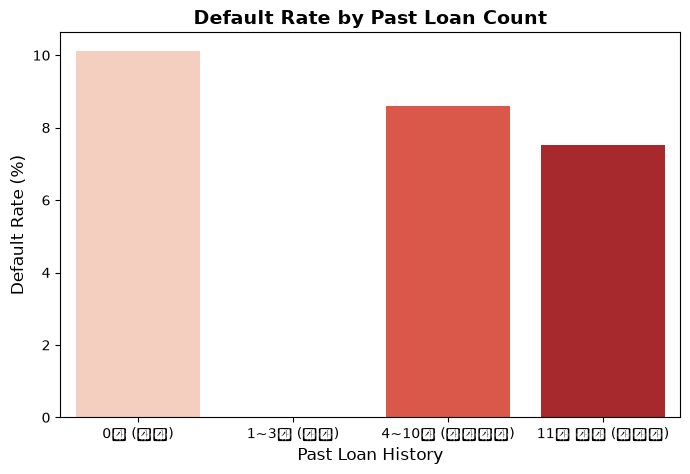

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 전체 고객의 기본 연체율(Default Rate) 확인
print("=== 전체 고객 연체율 (Default Rate) ===")
# 0은 정상 상환, 1은 대출 연체를 의미합니다.
print(df_mart['TARGET'].value_counts(normalize=True) * 100)

# 2. SQL로 뽑아온 '과거 대출 횟수(PAST_LOAN_COUNT)' 구간화(Binning)
# 연속된 숫자를 비즈니스 그룹(신규, 적정, 다중채무 위험 등)으로 묶어줍니다.
df_mart['LOAN_COUNT_GROUP'] = pd.cut(df_mart['PAST_LOAN_COUNT'], 
                                     bins=[-1, 0, 3, 10, 100], 
                                     labels=['0건 (신규)', '1~3건 (적정)', '4~10건 (다중채무)', '11건 이상 (고위험)'])

# 3. 각 그룹별 실제 연체 발생 확률(평균) 계산
risk_by_loan_count = df_mart.groupby('LOAN_COUNT_GROUP')['TARGET'].mean() * 100

print("\n=== 과거 대출 횟수 그룹별 연체율 (%) ===")
print(risk_by_loan_count)

# 4. 포트폴리오 제안서에 삽입할 리스크 분석 시각화
plt.figure(figsize=(8, 5))
sns.barplot(x=risk_by_loan_count.index, y=risk_by_loan_count.values, palette='Reds')
plt.title('Default Rate by Past Loan Count', fontsize=14, fontweight='bold')
plt.ylabel('Default Rate (%)', fontsize=12)
plt.xlabel('Past Loan History', fontsize=12)
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import pandas as pd

# 1. 불필요한 ID 및 시각화용 임시 변수 제거 (문제지 X와 정답지 y 분리)
X = df_mart.drop(['SK_ID_CURR', 'TARGET', 'LOAN_COUNT_GROUP'], axis=1)
y = df_mart['TARGET']

# 2. 원핫 인코딩 (One-Hot Encoding)
# 인공지능은 'M', 'F' 같은 문자를 이해하지 못하므로, 성별(CODE_GENDER)을 0과 1의 숫자로 변환합니다.
X_encoded = pd.get_dummies(X, columns=['CODE_GENDER'], drop_first=True)

# 3. 결측치(NaN) 처리
# 금융 데이터는 고객이 입력하지 않은 빈칸이 매우 많습니다. 이를 해당 컬럼의 '평균값'으로 채워줍니다.
imputer = SimpleImputer(strategy='mean')
X_imputed = pd.DataFrame(imputer.fit_transform(X_encoded), columns=X_encoded.columns)

# 4. 학습용/실전용 데이터 분리 (8:2 비율)
# stratify=y 옵션으로 8%의 연체율을 양쪽에 공평하게 배분합니다.
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

print("✅ 모델링 전처리 완료!")
print(f"학습용 문제지 크기: {X_train.shape}")
print(f"실전용 문제지 크기: {X_test.shape}")

✅ 모델링 전처리 완료!
학습용 문제지 크기: (1476052, 6)
실전용 문제지 크기: (369014, 6)


In [10]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. 현업 금융권 표준 앙상블 모델 선언
lgbm = LGBMClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# 2. 대용량 데이터 모델 학습
print("🚀 LightGBM 모델 학습 시작...")
lgbm.fit(X_train, y_train)

# 3. 예측 및 평가
y_pred_lgbm = lgbm.predict(X_test)
y_pred_proba_lgbm = lgbm.predict_proba(X_test)[:, 1]

print("\n=== LightGBM 분류 성능 평가 ===")
print(classification_report(y_test, y_pred_lgbm))
roc_auc_lgbm = roc_auc_score(y_test, y_pred_proba_lgbm)
print(f"🔥 LightGBM 대회 공식 지표 (ROC-AUC Score): {roc_auc_lgbm:.4f}")

🚀 LightGBM 모델 학습 시작...
[LightGBM] [Info] Number of positive: 119160, number of negative: 1356892
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010301 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 756
[LightGBM] [Info] Number of data points in the train set: 1476052, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000

=== LightGBM 분류 성능 평가 ===
              precision    recall  f1-score   support

           0       0.94      0.62      0.75    339224
           1       0.12      0.58      0.20     29790

    accuracy                           0.61    369014
   macro avg       0.53      0.60      0.47    369014
weighted avg       0.88      0.61      0.70    369014

🔥 LightGBM 대회 공식 지표 (ROC-AUC Score): 0.6469


In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Scikit-learn 내장형 그래디언트 부스팅 모델 선언 (맥 libomp 에러 완벽 회피)
# class_weight='balanced'를 통해 8%의 연체 고객 데이터에 자동으로 가중치를 부여합니다.
hgb = HistGradientBoostingClassifier(random_state=42, class_weight='balanced')

# 2. 대용량 데이터 모델 학습
print("🚀 HistGradientBoosting 모델 학습 시작... (92만 건 학습, 약 30초~1분 소요)")
hgb.fit(X_train, y_train)

# 3. 실전 시험 예측
y_pred = hgb.predict(X_test)
y_pred_proba = hgb.predict_proba(X_test)[:, 1]

# 4. 성능 평가 리포트 및 ROC-AUC 확인
print("\n=== HistGradientBoosting 분류 성능 평가 ===")
print(classification_report(y_test, y_pred))

# 5. 캐글 대회 공식 평가지표
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"🔥 대회 공식 지표 (ROC-AUC Score): {roc_auc:.4f}")

🚀 HistGradientBoosting 모델 학습 시작... (92만 건 학습, 약 30초~1분 소요)

=== HistGradientBoosting 분류 성능 평가 ===
              precision    recall  f1-score   support

           0       0.94      0.61      0.74    339224
           1       0.12      0.59      0.20     29790

    accuracy                           0.61    369014
   macro avg       0.53      0.60      0.47    369014
weighted avg       0.88      0.61      0.70    369014

🔥 대회 공식 지표 (ROC-AUC Score): 0.6455


/var/folders/7x/sk93l0653q1g4q1lzbwmc4tc0000gn/T/ipykernel_3429/952560388.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Value", y="Feature", data=top_10_features, palette="viridis")


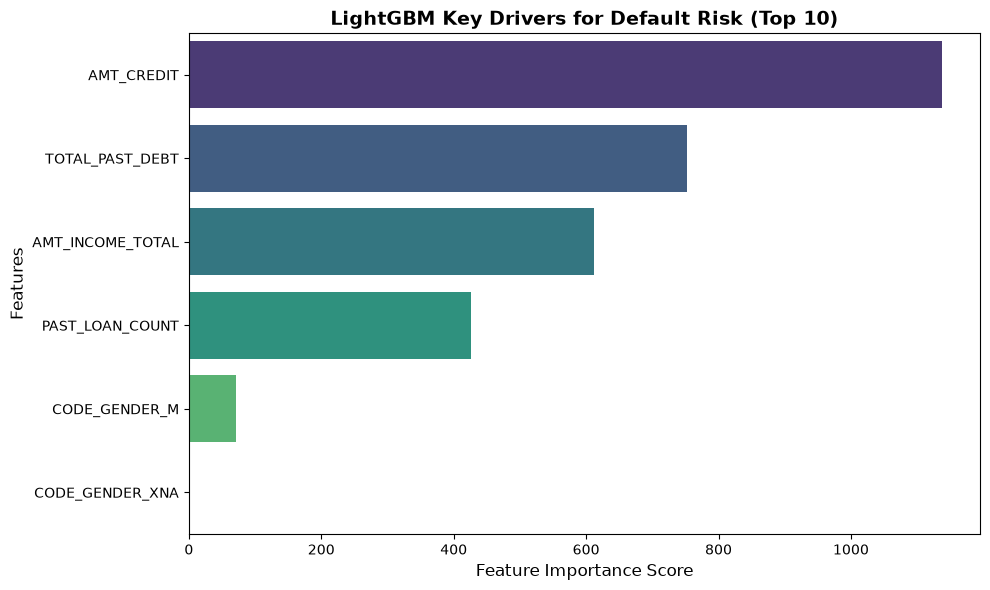

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 모델이 학습한 변수 중요도(Feature Importance) 추출
feature_imp = pd.DataFrame({
    'Value': lgbm.feature_importances_,
    'Feature': X_train.columns
})

# 2. 중요도 내림차순 정렬 후 상위 10개만 추출
top_10_features = feature_imp.sort_values(by="Value", ascending=False).head(10)

# 3. 비즈니스 리포트용 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x="Value", y="Feature", data=top_10_features, palette="viridis")
plt.title('LightGBM Key Drivers for Default Risk (Top 10)', fontsize=14, fontweight='bold')
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()